# Member 2 — Task 1: LightGBM Baseline on Engineered Features

**Role:** Member 2 (LightGBM Lead)  
**Branch:** `feat/m2-task1-lgbm-baseline`  
**Primary Metric:** Out-of-Fold Area Under the Precision-Recall Curve (**AUPRC** via `nn_data_pipeline.evaluate_auprc`)  
**Dataset:** `processed_data/train_lgbm.parquet` (`699,960` rows, `35` features) & `processed_data/test_lgbm.parquet` (`299,984` rows) produced by Member 1.

### Objectives
1. Build and export the reusable shared module `lgbm_pipeline.py` (using `%%writefile` per `requirement.md`).
2. Verify 100% alignment of `id`, `fold`, and `is_fraud` between `train_lgbm.parquet` and `train_folds.csv`, with zero missing/infinite values.
3. Establish clean 5-Fold Stratified CV baselines for default LightGBM:
   - **Baseline A (Control):** Original 24 raw features.
   - **Baseline B (Target):** Full 35 features (24 raw + 11 engineered features from Member 1).
4. Inspect Top-20 Feature Importance (`gain` and `split`) to quantify the real impact of Member 1's domain features.

## 1. Export Reusable Shared Module (`lgbm_pipeline.py`)

In [1]:
%%writefile lgbm_pipeline.py
"""Shared leak-free LightGBM cross-validation and evaluation pipeline for Member 2."""

import os
import time
from typing import Any, Iterable

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)

from nn_data_pipeline import (
    CAT_COLS,
    ENGINEERED_COLS,
    ID_COL,
    N_SPLITS,
    SEED,
    TARGET_COL,
    evaluate_auprc,
)

FOLD_COL = "fold"
TRAIN_LGBM_PATH = os.path.join("processed_data", "train_lgbm.parquet")
TEST_LGBM_PATH = os.path.join("processed_data", "test_lgbm.parquet")


def load_lgbm_datasets(
    train_path: str = TRAIN_LGBM_PATH,
    test_path: str = TEST_LGBM_PATH,
    verify_folds_path: str | None = "train_folds.csv",
    verify_test_raw_path: str | None = "test.csv",
) -> tuple[pd.DataFrame, pd.DataFrame, list[str], list[str]]:
    """Load Member 1's LightGBM parquet artifacts and run strict integrity checks."""
    train_df = pd.read_parquet(train_path)
    test_df = pd.read_parquet(test_path)

    excluded = {ID_COL, FOLD_COL, TARGET_COL}
    feature_cols = [c for c in train_df.columns if c not in excluded]
    cat_cols = [c for c in CAT_COLS if c in feature_cols]

    # Verify identical feature schema between train and test
    test_feature_cols = [c for c in test_df.columns if c != ID_COL]
    if feature_cols != test_feature_cols:
        raise ValueError("Train and test feature columns do not match in name or order.")

    # Verify zero Inf values in numeric columns
    num_tr = train_df[feature_cols].select_dtypes(include=[np.number]).to_numpy(dtype=np.float64)
    num_te = test_df[feature_cols].select_dtypes(include=[np.number]).to_numpy(dtype=np.float64)
    if np.isinf(num_tr).any() or np.isinf(num_te).any():
        raise ValueError("Infinite values detected in LightGBM numeric features.")

    # Verify exact row alignment with shared train_folds.csv if present
    if verify_folds_path and os.path.exists(verify_folds_path):
        tf = pd.read_csv(verify_folds_path, usecols=[ID_COL, FOLD_COL, TARGET_COL])
        if not np.array_equal(train_df[ID_COL].to_numpy(), tf[ID_COL].to_numpy()):
            raise ValueError("ID misalignment between train_lgbm.parquet and train_folds.csv.")
        if not np.array_equal(train_df[FOLD_COL].to_numpy(), tf[FOLD_COL].to_numpy()):
            raise ValueError("Fold misalignment between train_lgbm.parquet and train_folds.csv.")
        if not np.array_equal(
            train_df[TARGET_COL].astype(int).to_numpy(),
            tf[TARGET_COL].astype(int).to_numpy(),
        ):
            raise ValueError("Target misalignment between train_lgbm.parquet and train_folds.csv.")

    # Verify exact row alignment with raw test.csv if present
    if verify_test_raw_path and os.path.exists(verify_test_raw_path):
        te_raw = pd.read_csv(verify_test_raw_path, usecols=[ID_COL])
        if not np.array_equal(test_df[ID_COL].to_numpy(), te_raw[ID_COL].to_numpy()):
            raise ValueError("ID misalignment between test_lgbm.parquet and test.csv.")

    return train_df, test_df, feature_cols, cat_cols


def compute_scale_pos_weight(y_train: np.ndarray, mode: str | float = "none") -> float:
    """Compute class weight strictly from a training fold target vector."""
    if isinstance(mode, (int, float)) and not isinstance(mode, bool):
        return float(mode)

    y_arr = np.asarray(y_train, dtype=np.int64)
    n_neg = int(np.sum(y_arr == 0))
    n_pos = int(np.sum(y_arr == 1))
    if n_pos == 0:
        raise ValueError("Training fold contains zero positive samples.")

    ratio = n_neg / n_pos
    mode_key = str(mode).lower()
    if mode_key == "none":
        return 1.0
    if mode_key == "balanced":
        return float(ratio)
    if mode_key == "sqrt":
        return float(np.sqrt(ratio))
    raise ValueError(f"Unsupported scale_pos_weight mode: {mode}")


def evaluate_predictions(
    y_true: np.ndarray,
    y_pred_proba: np.ndarray,
    verbose: bool = False,
) -> dict[str, Any]:
    """Evaluate continuous fraud probabilities using AUPRC (primary) and auxiliary metrics."""
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_pred_proba, dtype=np.float64)

    auprc = evaluate_auprc(y_true_arr, y_prob_arr)
    roc_auc = float(roc_auc_score(y_true_arr, y_prob_arr))

    precisions, recalls, thresholds = precision_recall_curve(y_true_arr, y_prob_arr)
    f1_scores = np.divide(
        2.0 * precisions * recalls,
        precisions + recalls,
        out=np.zeros_like(precisions),
        where=(precisions + recalls) > 0,
    )
    best_idx = int(np.argmax(f1_scores))
    best_threshold = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5
    best_f1 = float(f1_scores[best_idx])
    best_precision = float(precisions[best_idx])
    best_recall = float(recalls[best_idx])
    f1_at_05 = float(f1_score(y_true_arr, (y_prob_arr >= 0.5).astype(int), zero_division=0))
    cm = confusion_matrix(y_true_arr, (y_prob_arr >= best_threshold).astype(int))

    if verbose:
        print("=" * 56)
        print(f"OOF AUPRC (Primary) : {auprc:.6f}")
        print(f"OOF ROC-AUC         : {roc_auc:.6f}")
        print(f"F1 @ 0.50           : {f1_at_05:.6f}")
        print(
            f"Best F1             : {best_f1:.6f} @ threshold={best_threshold:.4f} "
            f"(P={best_precision:.4f}, R={best_recall:.4f})"
        )
        print(f"Confusion Matrix (Best Thresh):\n{cm}")
        print("=" * 56)

    return {
        "auprc": auprc,
        "roc_auc": roc_auc,
        "f1_at_05": f1_at_05,
        "best_f1": best_f1,
        "best_threshold": best_threshold,
        "best_precision": best_precision,
        "best_recall": best_recall,
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    }


def get_default_lgbm_params(seed: int = SEED) -> dict[str, Any]:
    """Return clean baseline LightGBM hyperparameters for binary fraud detection."""
    return {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "learning_rate": 0.05,
        "n_estimators": 2000,
        "num_leaves": 31,
        "max_depth": -1,
        "subsample": 1.0,
        "subsample_freq": 0,
        "colsample_bytree": 1.0,
        "min_child_samples": 20,
        "reg_alpha": 0.0,
        "reg_lambda": 0.0,
        "random_state": seed,
        "n_jobs": -1,
        "verbose": -1,
    }


def run_lgbm_cv(
    train_df: pd.DataFrame,
    feature_cols: list[str],
    params: dict[str, Any] | None = None,
    test_df: pd.DataFrame | None = None,
    cat_cols: list[str] | None = None,
    spw_mode: str | float | None = None,
    stopping_rounds: int = 100,
    seeds: Iterable[int] = (SEED,),
    verbose: bool = True,
) -> dict[str, Any]:
    """Run leak-free Stratified 5-Fold LightGBM CV using train_df['fold']."""
    start_time = time.perf_counter()
    seeds_list = list(seeds)
    base_params = get_default_lgbm_params()
    if params is not None:
        base_params.update(params)

    if cat_cols is None:
        cat_cols = [c for c in CAT_COLS if c in feature_cols]

    X_all = train_df[feature_cols]
    y_all = train_df[TARGET_COL].astype(np.int64).to_numpy()
    folds = train_df[FOLD_COL].to_numpy()
    X_test = test_df[feature_cols] if test_df is not None else None

    oof_preds = np.zeros(len(train_df), dtype=np.float64)
    test_preds = np.zeros(len(test_df), dtype=np.float64) if test_df is not None else None

    fold_auprcs: list[float] = []
    best_iterations: list[int] = []
    gain_importances = np.zeros(len(feature_cols), dtype=np.float64)
    split_importances = np.zeros(len(feature_cols), dtype=np.float64)

    for fold in range(N_SPLITS):
        tr_mask = folds != fold
        va_mask = folds == fold

        X_tr, y_tr = X_all.loc[tr_mask], y_all[tr_mask]
        X_va, y_va = X_all.loc[va_mask], y_all[va_mask]

        fold_val_preds = np.zeros(int(va_mask.sum()), dtype=np.float64)
        fold_test_preds = np.zeros(len(test_df), dtype=np.float64) if X_test is not None else None
        fold_iters: list[int] = []

        for seed in seeds_list:
            fold_params = dict(base_params)
            fold_params["random_state"] = int(seed)
            fold_params["bagging_seed"] = int(seed)
            fold_params["feature_fraction_seed"] = int(seed)

            # Compute fold-local scale_pos_weight strictly on training fold
            if spw_mode is not None:
                fold_params.pop("is_unbalance", None)
                fold_params["scale_pos_weight"] = compute_scale_pos_weight(y_tr, mode=spw_mode)

            model = lgb.LGBMClassifier(**fold_params)
            callbacks = [lgb.early_stopping(stopping_rounds=stopping_rounds, verbose=False)]

            model.fit(
                X_tr,
                y_tr,
                eval_set=[(X_va, y_va)],
                eval_metric="average_precision",
                categorical_feature=cat_cols if cat_cols else "auto",
                callbacks=callbacks,
            )

            best_iter = int(model.best_iteration_ or fold_params.get("n_estimators", 2000))
            fold_iters.append(best_iter)

            fold_val_preds += model.predict_proba(X_va, num_iteration=best_iter)[:, 1] / len(seeds_list)
            if X_test is not None and fold_test_preds is not None:
                fold_test_preds += model.predict_proba(X_test, num_iteration=best_iter)[:, 1] / len(seeds_list)

            gain_importances += model.booster_.feature_importance(importance_type="gain") / (N_SPLITS * len(seeds_list))
            split_importances += model.booster_.feature_importance(importance_type="split") / (N_SPLITS * len(seeds_list))

        oof_preds[va_mask] = fold_val_preds
        if test_preds is not None and fold_test_preds is not None:
            test_preds += fold_test_preds / N_SPLITS

        fold_auprc = evaluate_auprc(y_va, fold_val_preds)
        fold_auprcs.append(fold_auprc)
        avg_iter = int(round(float(np.mean(fold_iters))))
        best_iterations.append(avg_iter)

        if verbose:
            print(f"Fold {fold} | AUPRC: {fold_auprc:.6f} | Best Iter: {avg_iter}")

    elapsed = time.perf_counter() - start_time
    overall = evaluate_predictions(y_all, oof_preds, verbose=verbose)
    mean_auprc = float(np.mean(fold_auprcs))
    std_auprc = float(np.std(fold_auprcs))

    if verbose:
        print(
            f"Mean 5-Fold AUPRC: {mean_auprc:.6f} +/- {std_auprc:.6f} "
            f"| Avg Best Iter: {np.mean(best_iterations):.1f} | Time: {elapsed:.1f}s"
        )

    fi_df = pd.DataFrame(
        {
            "feature": feature_cols,
            "gain": gain_importances,
            "split": split_importances,
            "is_engineered": [c in ENGINEERED_COLS for c in feature_cols],
        }
    ).sort_values("gain", ascending=False).reset_index(drop=True)
    fi_df["gain_pct"] = 100.0 * fi_df["gain"] / max(fi_df["gain"].sum(), 1e-12)

    return {
        "oof_preds": oof_preds,
        "test_preds": test_preds,
        "fold_auprcs": fold_auprcs,
        "mean_auprc": mean_auprc,
        "std_auprc": std_auprc,
        "metrics": overall,
        "best_iterations": best_iterations,
        "feature_importance_df": fi_df,
        "train_time_sec": float(elapsed),
    }

Overwriting lgbm_pipeline.py


## 2. Load Datasets & Verify Alignment with `train_folds.csv`

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from lgbm_pipeline import (
    CAT_COLS,
    ENGINEERED_COLS,
    FOLD_COL,
    ID_COL,
    TARGET_COL,
    get_default_lgbm_params,
    load_lgbm_datasets,
    run_lgbm_cv,
)

sns.set_theme(style="whitegrid")

train_df, test_df, all_feature_cols, cat_cols = load_lgbm_datasets()
raw_feature_cols = [c for c in all_feature_cols if c not in ENGINEERED_COLS]

print(f"Train shape          : {train_df.shape}")
print(f"Test shape           : {test_df.shape}")
print(f"Raw features         : {len(raw_feature_cols)}")
print(f"Engineered features  : {len(ENGINEERED_COLS)}")
print(f"Total LGBM features  : {len(all_feature_cols)}")
print(f"Categorical features : {cat_cols}")
print(
    f"Fraud rate           : {train_df[TARGET_COL].mean() * 100:.4f}% "
    f"({int(train_df[TARGET_COL].sum()):,} / {len(train_df):,})"
)
print("\nFold distribution:")
display(
    train_df.groupby(FOLD_COL)[TARGET_COL]
    .agg(total_rows="count", fraud_count="sum", fraud_rate=lambda s: round(s.mean() * 100, 4))
)

Train shape          : (699960, 38)
Test shape           : (299984, 36)
Raw features         : 24
Engineered features  : 11
Total LGBM features  : 35
Categorical features : ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Fraud rate           : 1.6700% (11,689 / 699,960)

Fold distribution:


,total_rows,fraud_count,fraud_rate
fold,,,
0,139992,2337,1.6694
1,139992,2338,1.6701
2,139992,2338,1.6701
3,139992,2338,1.6701
4,139992,2338,1.6701


## 3. Baseline Experiments (5-Fold Stratified CV)

We run two controlled LightGBM baselines with identical default hyperparameters (`learning_rate=0.05`, `num_leaves=31`, `early_stopping=100`, `eval_metric='average_precision'`):
- **Baseline A (Control):** 24 original features.
- **Baseline B (Target):** 35 features (24 original + 11 engineered features from Member 1).

In [3]:
baseline_params = get_default_lgbm_params(seed=42)

print(">>> Running Baseline A: Default LightGBM on 24 Raw Features")
res_raw = run_lgbm_cv(
    train_df=train_df,
    feature_cols=raw_feature_cols,
    params=baseline_params,
    cat_cols=cat_cols,
    stopping_rounds=100,
    verbose=True,
)

print("\n>>> Running Baseline B: Default LightGBM on 35 Engineered Features")
res_fe = run_lgbm_cv(
    train_df=train_df,
    feature_cols=all_feature_cols,
    params=baseline_params,
    cat_cols=cat_cols,
    stopping_rounds=100,
    verbose=True,
)

>>> Running Baseline A: Default LightGBM on 24 Raw Features
Fold 0 | AUPRC: 0.484756 | Best Iter: 309
Fold 1 | AUPRC: 0.500627 | Best Iter: 381
Fold 2 | AUPRC: 0.516346 | Best Iter: 292
Fold 3 | AUPRC: 0.496408 | Best Iter: 325
Fold 4 | AUPRC: 0.482367 | Best Iter: 283
OOF AUPRC (Primary) : 0.495767
OOF ROC-AUC         : 0.945159
F1 @ 0.50           : 0.434426
Best F1             : 0.487723 @ threshold=0.2298 (P=0.5070, R=0.4698)
Confusion Matrix (Best Thresh):
[[682931   5340]
 [  6197   5492]]
Mean 5-Fold AUPRC: 0.496101 +/- 0.012229 | Avg Best Iter: 318.0 | Time: 41.1s

>>> Running Baseline B: Default LightGBM on 35 Engineered Features
Fold 0 | AUPRC: 0.488077 | Best Iter: 261
Fold 1 | AUPRC: 0.505605 | Best Iter: 256
Fold 2 | AUPRC: 0.514097 | Best Iter: 215
Fold 3 | AUPRC: 0.504021 | Best Iter: 375
Fold 4 | AUPRC: 0.479946 | Best Iter: 119
OOF AUPRC (Primary) : 0.498015
OOF ROC-AUC         : 0.945109
F1 @ 0.50           : 0.434494
Best F1             : 0.491957 @ threshold=0.2577 

## 4. Comparison Leaderboard & Fold-by-Fold Analysis

In [4]:
summary_rows = []
for name, n_feats, res in [
    ("LGBM Baseline (24 Raw Features)", len(raw_feature_cols), res_raw),
    ("LGBM Baseline (35 Engineered Features)", len(all_feature_cols), res_fe),
]:
    m = res["metrics"]
    summary_rows.append(
        {
            "Experiment": name,
            "Num_Features": n_feats,
            "Mean_Fold_AUPRC": res["mean_auprc"],
            "Std_Fold_AUPRC": res["std_auprc"],
            "OOF_AUPRC": m["auprc"],
            "OOF_ROC_AUC": m["roc_auc"],
            "F1_at_0.50": m["f1_at_05"],
            "Best_F1": m["best_f1"],
            "Best_Threshold": m["best_threshold"],
            "Avg_Best_Iter": float(np.mean(res["best_iterations"])),
            "Train_Time_Sec": res["train_time_sec"],
        }
    )

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

delta_auprc = res_fe["metrics"]["auprc"] - res_raw["metrics"]["auprc"]
print(f"\nAUPRC Delta (35 FE vs 24 Raw): {delta_auprc:+.6f}")

fold_compare_df = pd.DataFrame(
    {
        "Fold": list(range(5)),
        "Raw_24_AUPRC": res_raw["fold_auprcs"],
        "FE_35_AUPRC": res_fe["fold_auprcs"],
        "Delta": np.array(res_fe["fold_auprcs"]) - np.array(res_raw["fold_auprcs"]),
        "FE_Best_Iter": res_fe["best_iterations"],
    }
)
display(fold_compare_df)


AUPRC Delta (35 FE vs 24 Raw): +0.002248


,Experiment,Num_Features,Mean_Fold_AUPRC,Std_Fold_AUPRC,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Avg_Best_Iter,Train_Time_Sec
0,LGBM Baseline (24 Raw Features),24,0.496101,0.012229,0.495767,0.945159,0.434426,0.487723,0.229798,318.0,41.137404
1,LGBM Baseline (35 Engineered Features),35,0.498349,0.012466,0.498015,0.945109,0.434494,0.491957,0.257673,245.2,39.149390


,Fold,Raw_24_AUPRC,FE_35_AUPRC,Delta,FE_Best_Iter
0,0,0.484756,0.488077,0.003321,261
1,1,0.500627,0.505605,0.004978,256
2,2,0.516346,0.514097,-0.002250,215
3,3,0.496408,0.504021,0.007613,375
4,4,0.482367,0.479946,-0.002421,119


## 5. Feature Importance & Diagnostic Plots

Top 20 Features by Total Gain (35-Feature Baseline):

Total Gain Share of Member 1's 11 Engineered Features: 25.96%

Engineered Feature Ranking:


,feature,gain,split,is_engineered,gain_pct
0,cvv_retry_count,121275.261604,264.4,False,23.469882
1,total_risk_flags,119915.466546,335.6,True,23.206727
2,merchant_risk_score,90035.227228,964.4,False,17.424132
3,velocity_score,62302.487621,925.6,False,12.057134
4,auth_method,39036.022250,263.6,False,7.554474
5,customer_age,23678.299204,652.8,False,4.582360
6,hours_since_last_txn,6511.242587,447.2,False,1.260093
7,merchant_category,5485.503366,262.6,False,1.061586
8,amount_usd,4801.995323,341.8,False,0.929310
9,account_balance_usd,4325.644888,341.0,False,0.837124


,feature,gain,split,is_engineered,gain_pct
0,total_risk_flags,119915.466546,335.6,True,23.206727
1,travel_speed_kmh,3750.892575,277.2,True,0.725894
2,amount_per_txn_24h,3700.119987,264.8,True,0.716068
3,amount_to_balance_ratio,3326.813286,244.2,True,0.643824
4,hour_cos,1843.561974,133.6,True,0.356777
5,hour_sin,1537.077099,116.4,True,0.297464
6,is_night_txn,34.714376,2.2,True,0.006718
7,is_over_balance,8.855244,0.8,True,0.001714
8,is_weekend,3.051074,0.4,True,0.000590
9,has_cvv_retry,0.000000,0.0,True,0.000000


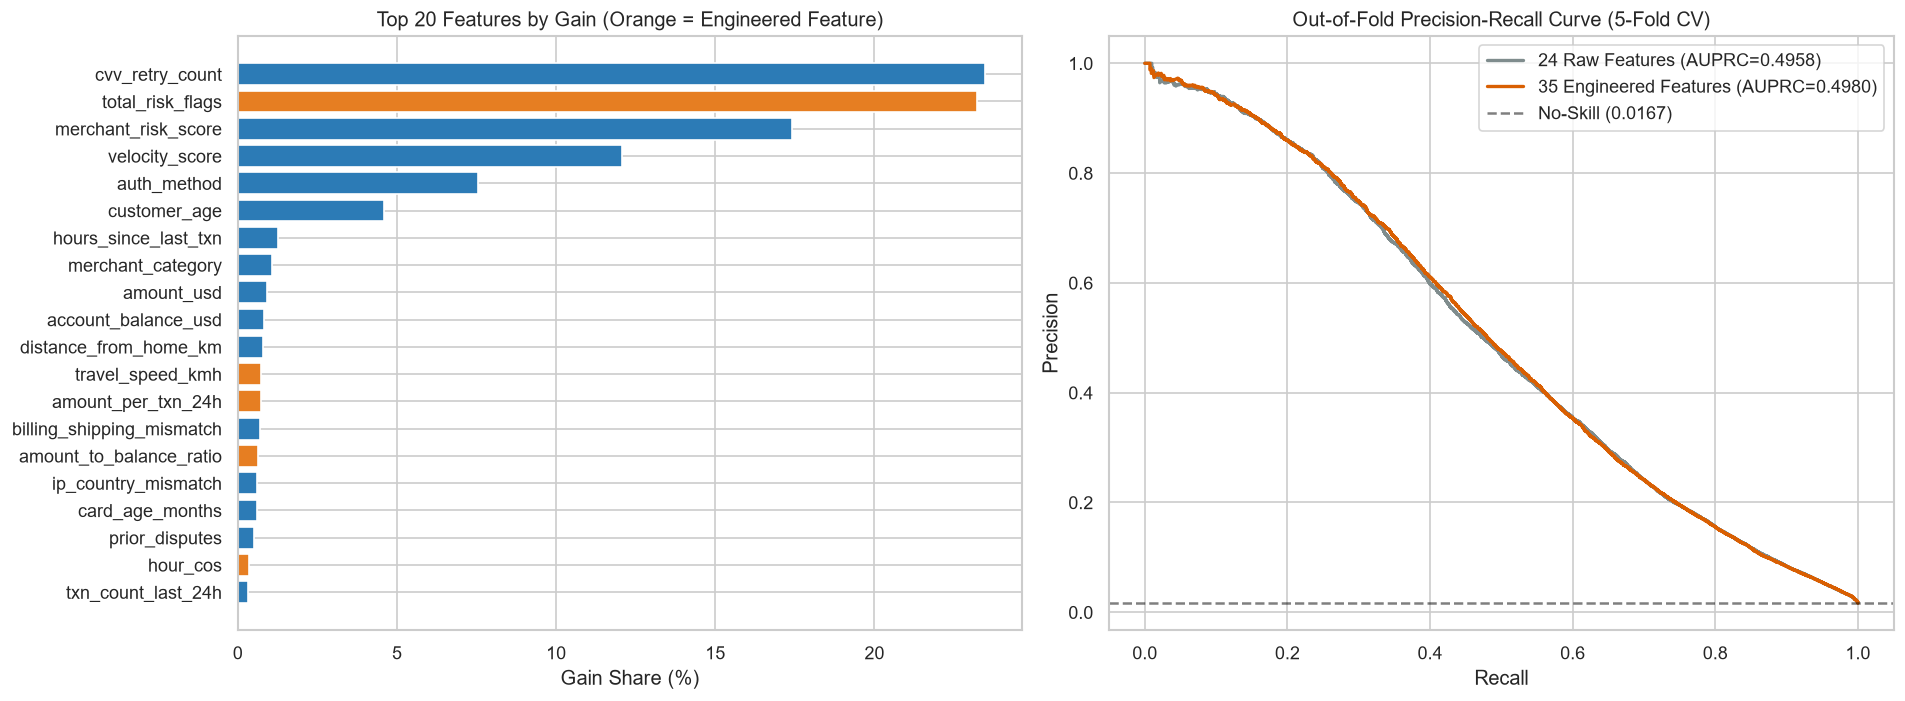

In [5]:
fi_df = res_fe["feature_importance_df"]
print("Top 20 Features by Total Gain (35-Feature Baseline):")
display(fi_df.head(20))

eng_gain_pct = fi_df.loc[fi_df["is_engineered"], "gain_pct"].sum()
print(f"\nTotal Gain Share of Member 1's 11 Engineered Features: {eng_gain_pct:.2f}%")
print("\nEngineered Feature Ranking:")
display(fi_df[fi_df["is_engineered"]].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Top 20 Features by Gain
top20 = fi_df.head(20).iloc[::-1]
colors = ["#e67e22" if eng else "#2c7bb6" for eng in top20["is_engineered"]]
axes[0].barh(top20["feature"], top20["gain_pct"], color=colors)
axes[0].set_xlabel("Gain Share (%)")
axes[0].set_title("Top 20 Features by Gain (Orange = Engineered Feature)")

# Plot 2: Out-of-Fold Precision-Recall Curve
y_true = train_df[TARGET_COL].to_numpy()
for label, res, color in [
    (f"24 Raw Features (AUPRC={res_raw['metrics']['auprc']:.4f})", res_raw, "#7f8c8d"),
    (f"35 Engineered Features (AUPRC={res_fe['metrics']['auprc']:.4f})", res_fe, "#d95f02"),
]:
    p, r, _ = precision_recall_curve(y_true, res["oof_preds"])
    axes[1].plot(r, p, label=label, linewidth=2, color=color)

axes[1].axhline(y_true.mean(), linestyle="--", color="black", alpha=0.5, label=f"No-Skill ({y_true.mean():.4f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Out-of-Fold Precision-Recall Curve (5-Fold CV)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 6. Coreach.ai Progress Log Comment

In [6]:
print(
    f"Coreach.ai Comment -> LGBM Baseline + 35 Engineered Features "
    f"| CV OOF AUPRC: {res_fe['metrics']['auprc']:.4f} "
    f"(Mean Fold: {res_fe['mean_auprc']:.4f} +/- {res_fe['std_auprc']:.4f})"
)

Coreach.ai Comment -> LGBM Baseline + 35 Engineered Features | CV OOF AUPRC: 0.4980 (Mean Fold: 0.4983 +/- 0.0125)
